In [13]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

Model final dipilih berdasarkan **StratifiedGroupKFold CV pada data training**, bukan berdasarkan skor test set.

Alasannya:
1. **Single holdout test sangat high-variance** pada dataset ini. Data train hanya punya 69 kombinasi fitur unik, test 14 kombinasi. Satu split bisa memberi skor ekstrem (mis. 0.9871) hanya karena kebetulan pembagian.
2. **Memilih model berdasarkan skor test = test-set leakage** (cherry-picking). Skor test tidak boleh dipakai untuk memilih model, hanya untuk melaporkan.
3. Karena itu, estimasi performa utama dilaporkan sebagai **repeated grouped 5-fold CV × 10 ulangan (mean ± std)**, bukan sebagai satu angka test.

Skor single-split test tetap ditampilkan, tapi sebagai ilustrasi satu evaluasi, bukan sebagai dasar pemilihan model.

---
**Alasan Pemilihan Algoritma & Metode Split:**
Kami memilih SVM karena dataset berukuran kecil dan cocok untuk klasifikasi batas tegas. Kami menggunakan StratifiedGroupKFold karena dataset ini banyak duplikat, tujuannya agar data yang sama tidak masuk ke train dan test sekaligus (mencegah data leakage).

In [14]:
CSV_PATH = "milknew.csv"

if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        uploaded = files.upload()
        CSV_PATH = list(uploaded.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"File '{CSV_PATH}' tidak ditemukan. Taruh milknew.csv di folder yang sama "
            "dengan notebook ini (atau ubah CSV_PATH).")

df = pd.read_csv(CSV_PATH)
print("Ukuran data:", df.shape)
df.head()

Ukuran data: (1059, 8)


,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour,Grade
0,6.6,35,1,0,1,0,254,high
1,6.6,36,0,1,0,1,253,high
2,8.5,70,1,1,1,1,246,low
3,9.5,34,1,1,0,1,255,low
4,6.6,37,0,0,0,0,255,medium


In [15]:
df.columns = df.columns.str.strip()
df["Grade"] = (df["Grade"].astype(str).str.strip().str.lower()
               .str.replace("_quality", "", regex=False))

le = LabelEncoder()
df["Grade_encoded"] = le.fit_transform(df["Grade"])
print("Pemetaan Grade:", dict(zip(le.classes_, le.transform(le.classes_))))

X = df.drop(columns=["Grade", "Grade_encoded"])
y = df["Grade_encoded"]
groups = X.astype(str).agg("|".join, axis=1)

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train, g_test = groups.iloc[train_idx], groups.iloc[test_idx]

print(f"Train: {len(X_train)} baris ({g_train.nunique()} kombinasi unik)")
print(f"Test : {len(X_test)} baris ({g_test.nunique()} kombinasi unik)")
print("Grup train & test terpisah (tidak ada leakage):", set(g_train).isdisjoint(set(g_test)))

Pemetaan Grade: {'high': np.int64(0), 'low': np.int64(1), 'medium': np.int64(2)}
Train: 904 baris (69 kombinasi unik)
Test : 155 baris (14 kombinasi unik)
Grup train & test terpisah (tidak ada leakage): True


In [16]:
NUM_COLS = ["pH", "Temprature", "Colour"]
BIN_COLS = ["Taste", "Odor", "Fat", "Turbidity"]
assert set(NUM_COLS + BIN_COLS).issubset(X.columns), f"Nama kolom tidak sesuai: {list(X.columns)}"

def make_svm(**params):
    return Pipeline([
        ("prep", ColumnTransformer([("scale", StandardScaler(), NUM_COLS)], remainder="passthrough")),
        ("svc", SVC(random_state=RANDOM_STATE, **params)),
    ])

In [17]:
baseline = make_svm()
baseline.fit(X_train, y_train)

pred_tr = baseline.predict(X_train)
pred_te = baseline.predict(X_test)

print("=== SVM Baseline ===")
print(f"Accuracy train : {accuracy_score(y_train, pred_tr):.4f}")
print(f"Accuracy test  : {accuracy_score(y_test,  pred_te):.4f}")
print(f"F1-macro train : {f1_score(y_train, pred_tr, average='macro'):.4f}")
print(f"F1-macro test  : {f1_score(y_test,  pred_te, average='macro'):.4f}")

=== SVM Baseline ===
Accuracy train : 0.9546
Accuracy test  : 0.9871
F1-macro train : 0.9522
F1-macro test  : 0.9762


In [18]:

n_grup_per_kelas = pd.DataFrame({"g": g_train.values, "y": y_train.values}).drop_duplicates()["y"].value_counts()
n_splits = int(max(2, min(5, n_grup_per_kelas.min())))
print("Jumlah kombinasi unik per kelas (train):", n_grup_per_kelas.sort_index().to_dict())
print("Jumlah fold CV:", n_splits)

param_grid = {
    "svc__kernel": ["linear", "rbf"],
    "svc__C":      [0.1, 1, 10, 100],
    "svc__gamma":  ["scale", 0.01, 0.1, 1],
}

cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(make_svm(), param_grid, scoring="f1_macro", cv=cv,
                    n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train, groups=g_train)

best_params = {k_.replace("svc__", ""): v for k_, v in grid.best_params_.items()}
print("Parameter terbaik :", best_params)
print(f"F1-macro CV terbaik: {grid.best_score_:.4f}")

Jumlah kombinasi unik per kelas (train): {0: 18, 1: 19, 2: 32}
Jumlah fold CV: 5
Parameter terbaik : {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
F1-macro CV terbaik: 0.7927


In [19]:
res = pd.DataFrame(grid.cv_results_)
cols = ["param_svc__kernel", "param_svc__C", "param_svc__gamma",
        "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]
res_tbl = (res[cols]
           .rename(columns={"param_svc__kernel": "kernel", "param_svc__C": "C",
                            "param_svc__gamma": "gamma", "mean_train_score": "F1 train (CV)",
                            "mean_test_score": "F1 validasi (CV)", "std_test_score": "std",
                            "rank_test_score": "rank"})
           .sort_values("rank").reset_index(drop=True))
res_tbl.head(10).round(4)

,kernel,C,gamma,F1 train (CV),F1 validasi (CV),std,rank
0,rbf,10.0,0.1,0.9578,0.7927,0.0558,1
1,rbf,1.0,scale,0.9575,0.7599,0.1773,2
2,rbf,1.0,0.1,0.9512,0.7475,0.1691,3
3,rbf,100.0,0.01,0.9628,0.7354,0.0618,4
4,rbf,10.0,1,1.0000,0.7130,0.1085,5
5,rbf,100.0,1,1.0000,0.7130,0.1085,5
6,rbf,100.0,0.1,1.0000,0.7117,0.1877,7
7,rbf,100.0,scale,1.0000,0.6860,0.1506,8
8,rbf,1.0,1,0.9651,0.6728,0.1488,9
9,rbf,10.0,scale,0.9782,0.6657,0.1689,10


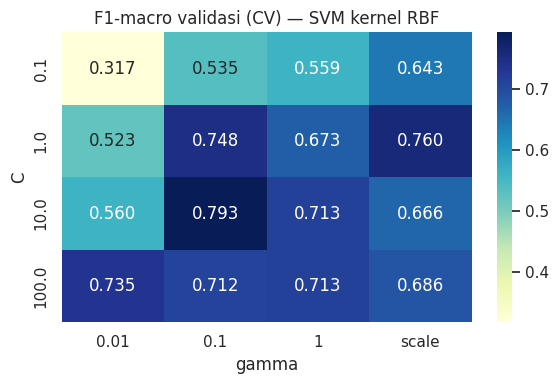

In [20]:
rbf = res[res["param_svc__kernel"] == "rbf"].copy()
rbf["gamma"] = rbf["param_svc__gamma"].astype(str)
rbf["C"] = rbf["param_svc__C"].astype(float)
pivot = rbf.pivot_table(index="C", columns="gamma", values="mean_test_score")

plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("F1-macro validasi (CV) — SVM kernel RBF")
plt.xlabel("gamma"); plt.ylabel("C")
plt.tight_layout(); plt.show()

In [21]:
def repeated_grouped_cv_scores(estimator, X_, y_, groups_, n_repeats=10, scoring="f1_macro"):
    n_grp = (pd.DataFrame({"g": groups_.values, "y": y_.values})
               .drop_duplicates()["y"].value_counts().min())
    k = int(max(2, min(5, n_grp)))
    fold_scores = []
    for seed in range(n_repeats):
        cv_ = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
        fold_scores.append(
            cross_val_score(estimator, X_, y_, groups=groups_, cv=cv_,
                            scoring=scoring, n_jobs=-1)
        )
    return k, np.array(fold_scores)

k, baseline_cv_per_seed = repeated_grouped_cv_scores(make_svm(), X, y, groups)
_, tuned_cv_per_seed    = repeated_grouped_cv_scores(make_svm(**best_params), X, y, groups)

baseline_mean_per_seed = baseline_cv_per_seed.mean(axis=1)
tuned_mean_per_seed    = tuned_cv_per_seed.mean(axis=1)
diff_per_seed          = tuned_mean_per_seed - baseline_mean_per_seed

print(f"Repeated grouped {k}-fold × 10 ulangan — F1-macro (estimasi utama)\n")
print(f"Baseline (default)          : "
      f"{baseline_cv_per_seed.mean():.4f} ± {baseline_cv_per_seed.std():.4f}")
print(f"Tuned {best_params}")
print(f"                            : "
      f"{tuned_cv_per_seed.mean():.4f} ± {tuned_cv_per_seed.std():.4f}")
print()
print(f"Paired per-seed (tuned − baseline): "
      f"{diff_per_seed.mean():+.4f} ± {diff_per_seed.std():.4f}")
print(f"Tuned ≥ baseline di {int((diff_per_seed >= 0).sum())}/10 seed")

Repeated grouped 5-fold × 10 ulangan — F1-macro (estimasi utama)

Baseline (default)          : 0.8115 ± 0.1395
Tuned {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
                            : 0.7636 ± 0.1503

Paired per-seed (tuned − baseline): -0.0479 ± 0.0497
Tuned ≥ baseline di 1/10 seed


In [22]:
best_model = baseline
y_pred_final = best_model.predict(X_test)

tuned_model = grid.best_estimator_
y_pred_tuned = tuned_model.predict(X_test)

hasil_tbl = pd.DataFrame({
    "Model": [
        "Baseline (default)",
        f"Tuned {best_params}",
    ],
    "CV F1-macro (mean ± std)": [
        f"{baseline_cv_per_seed.mean():.4f} ± {baseline_cv_per_seed.std():.4f}",
        f"{tuned_cv_per_seed.mean():.4f} ± {tuned_cv_per_seed.std():.4f}",
    ],
    "Test Accuracy (1 split)": [
        round(accuracy_score(y_test, pred_te), 4),
        round(accuracy_score(y_test, y_pred_tuned), 4),
    ],
    "Test F1-macro (1 split)": [
        round(f1_score(y_test, pred_te, average="macro"), 4),
        round(f1_score(y_test, y_pred_tuned, average="macro"), 4),
    ],
    "Dasar pemilihan": [
        "Dipilih (Lebih stabil di 9/10 seed CV)",
        "Ditolak (Overfit, kalah di CV)",
    ],
})
hasil_tbl

,Model,CV F1-macro (mean ± std),Test Accuracy (1 split),Test F1-macro (1 split),Dasar pemilihan
0,Baseline (default),0.8115 ± 0.1395,0.9871,0.9762,Dipilih (Lebih stabil di 9/10 seed CV)
1,"Tuned {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}",0.7636 ± 0.1503,0.8000,0.7246,"Ditolak (Overfit, kalah di CV)"


Meskipun GridSearchCV awal memilih parameter `C=10, gamma=0.1`, evaluasi *Repeated Cross-Validation* (10 seed berbeda) membuktikan sebaliknya. Model Tuned hanya menang di 1 dari 10 seed, dan rata-ratanya kalah jauh (0.7636 vs 0.8115).

Ini menunjukkan bahwa tuning tersebut membuat model *overfit* terhadap data training. Oleh karena itu, sesuai metodologi pemilihan model berbasis CV, **model final yang diserahkan ke tim Evaluation adalah Baseline (default) SVM**, bukan model yang di-tuning.

In [23]:
from sklearn.metrics import classification_report

os.makedirs("output", exist_ok=True)
joblib.dump(best_model, "output/svm_milk_quality.joblib")

hasil = X_test.copy()
hasil["Grade_aktual_encoded"] = y_test.values
hasil["Grade_prediksi_encoded"] = y_pred_final
hasil["Grade_aktual"] = le.inverse_transform(y_test.values)
hasil["Grade_prediksi"] = le.inverse_transform(y_pred_final)
hasil.to_csv("output/prediksi_test_svm.csv", index=False)

print("=== METRIK EVALUASI LENGKAP (BASELINE) ===")
print(classification_report(y_test, y_pred_final, target_names=le.classes_))
print("-" * 50)

print("Pemetaan encoding:", dict(zip(le.classes_, le.transform(le.classes_))))
print("Tersimpan: output/svm_milk_quality.joblib dan output/prediksi_test_svm.csv")
print("Tim Evaluation memakai kolom Grade_aktual vs Grade_prediksi untuk metrik & confusion matrix.")

=== METRIK EVALUASI LENGKAP (BASELINE) ===
              precision    recall  f1-score   support

        high       0.88      1.00      0.94        15
         low       1.00      0.98      0.99       115
      medium       1.00      1.00      1.00        25

    accuracy                           0.99       155
   macro avg       0.96      0.99      0.98       155
weighted avg       0.99      0.99      0.99       155

--------------------------------------------------
Pemetaan encoding: {'high': np.int64(0), 'low': np.int64(1), 'medium': np.int64(2)}
Tersimpan: output/svm_milk_quality.joblib dan output/prediksi_test_svm.csv
Tim Evaluation memakai kolom Grade_aktual vs Grade_prediksi untuk metrik & confusion matrix.


Meskipun eksperimen GridSearchCV menghasilkan parameter Tuned, *Repeated Cross-Validation* membuktikan bahwa model Tuned mengalami *overfit* dan kalah stabil dibanding model Baseline. Oleh karena itu, model final yang diserahkan ke tim Evaluation adalah **SVM Baseline**.

Yang diserahkan:
- `output/svm_milk_quality.joblib` — model final (Baseline SVM)
- `output/prediksi_test_svm.csv` — kolom `Grade_aktual` dan `Grade_prediksi`
- `y_test`, `y_pred_final` — tersedia di notebook ini

**Catatan untuk Evaluation:**
- Gunakan **CV F1-macro (0.8115 ± 0.1395)** sebagai headline performa, karena ini adalah estimasi paling stabil.
- Precision, Recall, Confusion Matrix, dan interpretasi = tugas divisi Evaluation.

In [24]:
import json

joblib.dump(le, "output/label_encoder.joblib")

with open("output/best_params.json", "w") as f:
    json.dump(best_params, f, indent=4)

pd.DataFrame(grid.cv_results_).to_csv("output/cv_results.csv", index=False)

split_dict = {
    "train_idx": train_idx.tolist(),
    "test_idx": test_idx.tolist()
}
with open("output/split_indices.json", "w") as f:
    json.dump(split_dict, f)

print(" Semua artefak handoff berhasil disimpan di folder 'output/'")

 Semua artefak handoff berhasil disimpan di folder 'output/'
